# Teaching Notebook 01: Creating and Measuring a Qubit, from zero

This notebook is the hands-on companion to the guide **`01_Creating_and_Measuring_a_Qubit_Guide.docx`**.
It rebuilds the course's Notebook 01 slowly, one idea at a time, and adds the pieces the original skips:
what a qubit *is* as numbers, what a gate *does* arithmetically, what measurement and shots *mean*,
and a home-made "quantum computer" in ten lines of NumPy so the simulator stops being a black box.

**How to use it**

* Run it top to bottom: menu **Kernel → Restart Kernel and Run All Cells** (or Shift + Enter on each cell in order).
* Each section has the same rhythm: a short explanation → code → *What to notice*.
* Change numbers and re-run; you cannot break anything.
* Exercises with solutions are at the end.

| Section | Topic | Guide section |
|---|---|---|
| 0 | Setup | 8.2, 8.3 |
| 1 | Classical bits | 2 |
| 2 | A qubit is a list of two numbers | 3.3 – 3.5 |
| 3 | The Bloch sphere | 3.6 |
| 4 | The X gate, by hand and in Qiskit | 4 |
| 5 | Measurement by hand: a ten-line quantum computer | 5 |
| 6 | The course notebook's circuit, rebuilt | 6 |
| 7 | Running on the simulator: shots and counts | 7.2, 7.3 |
| 8 | Histograms and the control experiment | 7.4 |
| 9 | A common mistake: re-running a cell | 8.5 |
| 10 | Why shots matter: a qubit that is *not* certain | 7.2 |
| 11 | Bonus: what a real, noisy machine might say | 10.3 |
| 12 | Exercises and solutions | 12 |


## 0. Setup

If Qiskit is not installed yet, remove the `#` in front of the `!pip` line and run the cell once.
(`!` runs a system command; `pip` is Python's package installer.)

The `import` lines bring in the tools we need:

* **NumPy** (`np`): arrays of numbers and arithmetic on them. We use it to do the quantum maths by hand.
* **Matplotlib** (`plt`): Python's standard plotting library.
* **Qiskit** pieces: `QuantumCircuit` (build circuits), `AerSimulator` (run them), `Statevector` and `Operator` (look at the exact maths), and two drawing helpers.

In [1]:
# !pip install -q qiskit qiskit-aer pylatexenc matplotlib

import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from itertools import product

import qiskit
import qiskit_aer
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram, plot_bloch_vector

# Colours used throughout: blue for outcome 0, orange for outcome 1
C0, C1 = "#2a78d6", "#eb6834"

print("Qiskit version:", qiskit.__version__)
print("Qiskit Aer version:", qiskit_aer.__version__)

Qiskit version: 2.5.2
Qiskit Aer version: 0.17.2


## 1. Classical bits

A **bit** is a 0 or a 1. With *n* bits there are $2^n$ possible patterns, and each extra bit doubles the count.
`product([0, 1], repeat=n)` lists every pattern for us.

In [2]:
for n in [1, 2, 3]:
    patterns = ["".join(str(b) for b in bits) for bits in product([0, 1], repeat=n)]
    print(f"{n} bit(s): {len(patterns)} patterns -> {patterns}")

print()
print("2**n for n = 1..10:", [2**n for n in range(1, 11)])

1 bit(s): 2 patterns -> ['0', '1']
2 bit(s): 4 patterns -> ['00', '01', '10', '11']
3 bit(s): 8 patterns -> ['000', '001', '010', '011', '100', '101', '110', '111']

2**n for n = 1..10: [2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]


Everything a computer stores is bits. For example the letter "A" is the number 65, stored as 8 bits:

In [3]:
letter = "A"
print(f"'{letter}' is number {ord(letter)}, stored as bits {format(ord(letter), '08b')}")

'A' is number 65, stored as bits 01000001


The simplest gate on a bit is **NOT**: it flips 0 ↔ 1. Here it is as a Python function, with its truth table.
Keep it in mind: the quantum **X gate** in Section 4 has exactly the same table.

In [4]:
def NOT(bit):
    return 1 - bit

print("input | NOT")
for bit in [0, 1]:
    print(f"  {bit}   |  {NOT(bit)}")

input | NOT
  0   |  1
  1   |  0


## 2. A qubit is a list of two numbers

A qubit's complete state (its **state vector**) is two numbers called **amplitudes**, written as a column:

$$|\psi\rangle = \begin{bmatrix} a \\ b \end{bmatrix}
\qquad a \text{ belongs to outcome } 0, \quad b \text{ belongs to outcome } 1.$$

The two special states are

$$|0\rangle = \begin{bmatrix} 1 \\ 0 \end{bmatrix} \text{ (always reads 0)}, \qquad
|1\rangle = \begin{bmatrix} 0 \\ 1 \end{bmatrix} \text{ (always reads 1)}.$$

**Born rule:** the probability of each outcome is its amplitude squared,

$$P(0) = |a|^2, \qquad P(1) = |b|^2, \qquad \text{and they must add to } 1.$$

In code, a state is just a NumPy array of two numbers.

In [5]:
ket0 = np.array([1, 0])          # |0>
ket1 = np.array([0, 1])          # |1>
psi  = np.array([0.6, 0.8])      # an example superposition

def probabilities(state):
    # Born rule: square the size of each amplitude
    return np.abs(state) ** 2

examples = {
    "|0>":       ket0,
    "|1>":       ket1,
    "psi":       psi,
    "equal mix": np.array([1, 1]) / np.sqrt(2),
}

print(f"{'state':10} {'amplitudes':>18} {'P(0)':>7} {'P(1)':>7} {'sum':>6}")
for name, state in examples.items():
    p0, p1 = probabilities(state)
    amps = f"[{state[0]:.3f}, {state[1]:.3f}]"
    print(f"{name:10} {amps:>18} {p0:7.2%} {p1:7.2%} {p0 + p1:6.2f}")

state              amplitudes    P(0)    P(1)    sum
|0>            [1.000, 0.000] 100.00%   0.00%   1.00
|1>            [0.000, 1.000]   0.00% 100.00%   1.00
psi            [0.600, 0.800]  36.00%  64.00%   1.00
equal mix      [0.707, 0.707]  50.00%  50.00%   1.00


**What to notice:** for `psi`, $0.6^2 = 0.36$ and $0.8^2 = 0.64$, so it reads 0 with 36% chance and 1 with 64% chance.
Every row sums to 1.

Not every pair of numbers is allowed. The squares must add to exactly 1 (**normalisation**):

In [6]:
def is_valid_state(state):
    return bool(np.isclose(probabilities(np.array(state)).sum(), 1.0))

for candidate in [[0.6, 0.8], [0.5, 0.5], [1, 0], [0.28, 0.96]]:
    total = probabilities(np.array(candidate)).sum()
    print(f"{candidate}: squares add to {total:.4f} -> valid? {is_valid_state(candidate)}")

[0.6, 0.8]: squares add to 1.0000 -> valid? True
[0.5, 0.5]: squares add to 0.5000 -> valid? False
[1, 0]: squares add to 1.0000 -> valid? True
[0.28, 0.96]: squares add to 1.0000 -> valid? True


The same four states as bar charts:

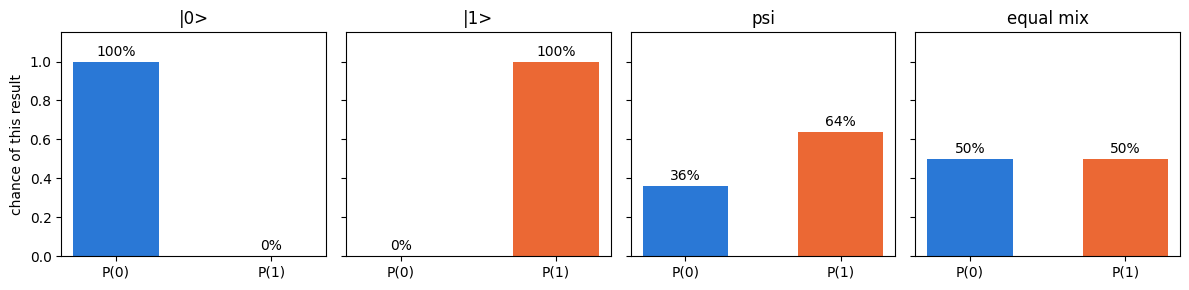

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3), sharey=True)
for ax, (name, state) in zip(axes, examples.items()):
    p = probabilities(state)
    ax.bar(["P(0)", "P(1)"], p, color=[C0, C1], width=0.55)
    for x, v in enumerate(p):
        ax.text(x, v + 0.03, f"{v:.0%}", ha="center")
    ax.set_title(name)
    ax.set_ylim(0, 1.15)
axes[0].set_ylabel("chance of this result")
plt.tight_layout()
plt.show()

Qiskit has the same idea built in. `Statevector` holds the amplitudes and `.probabilities()` applies the Born rule.
It gives exactly the numbers we computed by hand:

In [8]:
sv = Statevector([0.6, 0.8])
print("Qiskit Statevector:", sv)
print("Qiskit probabilities:", sv.probabilities())
print("Our probabilities:   ", probabilities(psi))

Qiskit Statevector: Statevector([0.6+0.j, 0.8+0.j],
            dims=(2,))
Qiskit probabilities: [0.36 0.64]
Our probabilities:    [0.36 0.64]


## 3. The Bloch sphere

Every single-qubit state can be drawn as an arrow on a globe: **north pole = |0⟩**, **south pole = |1⟩**,
equator = 50/50. For states with ordinary (real, non-negative) amplitudes $[a, b]$ the arrow's coordinates are

$$z = a^2 - b^2 \quad(\text{up/down}), \qquad x = 2ab \quad(\text{sideways}).$$

**Numerical example** for $[0.6, 0.8]$: $z = 0.36 - 0.64 = -0.28$ (a little below the equator, so 1 is a bit more likely)
and $x = 2 \times 0.6 \times 0.8 = 0.96$.

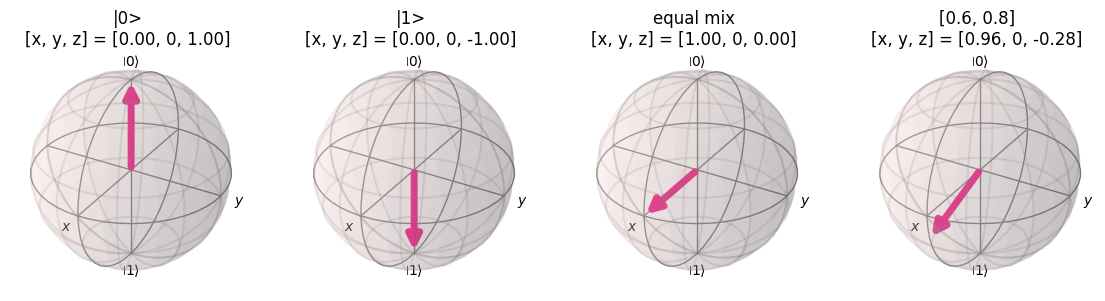

In [9]:
def bloch_coordinates(state):
    a, b = state
    return [2 * a * b, 0, a**2 - b**2]    # [x, y, z] for real amplitudes

states_to_draw = {"|0>": ket0, "|1>": ket1, "equal mix": examples["equal mix"], "[0.6, 0.8]": psi}

fig = plt.figure(figsize=(14, 3.8))
for i, (name, state) in enumerate(states_to_draw.items()):
    xyz = bloch_coordinates(state)
    ax = fig.add_subplot(1, 4, i + 1, projection="3d")
    plot_bloch_vector(xyz, ax=ax)
    ax.set_title(f"{name}\n[x, y, z] = [{xyz[0]:.2f}, {xyz[1]:.0f}, {xyz[2]:.2f}]", y=1.1)
plt.show()

**What to notice:** the arrow for $[0.6, 0.8]$ tips slightly towards the south pole, matching its 64% chance of reading 1.

## 4. The X gate, by hand and in Qiskit

A single-qubit gate is a 2 × 2 **matrix**. The X gate (quantum NOT) is

$$X = \begin{bmatrix} 0 & 1 \\ 1 & 0 \end{bmatrix}.$$

Applying it uses the **row-times-column** rule: each row of the matrix is multiplied entry by entry with the state, then added.
The function below prints every step of that arithmetic.

In [10]:
X = np.array([[0, 1],
              [1, 0]])

def apply_gate_verbose(gate, state, name="state"):
    new = gate @ state            # '@' is matrix multiplication in NumPy
    print(f"X applied to {name} = {state.tolist()}")
    for row in range(2):
        terms = " + ".join(f"{gate[row, col]}x{state[col]}" for col in range(2))
        print(f"  {'top' if row == 0 else 'bottom':6} = {terms} = {new[row]}")
    print(f"  result: {new.tolist()}   probabilities {probabilities(new).round(2).tolist()}")
    print()
    return new

apply_gate_verbose(X, ket0, "|0>")
apply_gate_verbose(X, ket1, "|1>")
apply_gate_verbose(X, psi,  "psi");

X applied to |0> = [1, 0]
  top    = 0x1 + 1x0 = 0
  bottom = 1x1 + 0x0 = 1
  result: [0, 1]   probabilities [0, 1]

X applied to |1> = [0, 1]
  top    = 0x0 + 1x1 = 1
  bottom = 1x0 + 0x1 = 0
  result: [1, 0]   probabilities [1, 0]

X applied to psi = [0.6, 0.8]
  top    = 0x0.6 + 1x0.8 = 0.8
  bottom = 1x0.6 + 0x0.8 = 0.6
  result: [0.8, 0.6]   probabilities [0.64, 0.36]



**What to notice:**
* X turns |0⟩ = [1, 0] into [0, 1] = |1⟩, and back. Same as NOT.
* On the superposition [0.6, 0.8] it **swaps the amplitudes**, so the probabilities swap from 36/64 to 64/36. A classical NOT can't do that.

Applying X twice gives the "do nothing" (**identity**) matrix. Two flips cancel:

In [11]:
print("X @ X =")
print(X @ X)
print("Is it the identity?", np.array_equal(X @ X, np.eye(2)))

X @ X =
[[1 0]
 [0 1]]
Is it the identity? True


Qiskit agrees. `Operator` shows the matrix of a circuit, and `Statevector.from_instruction` runs the exact maths
(no randomness, no measurement) to show the state the circuit produces.

In [12]:
x_only = QuantumCircuit(1)
x_only.x(0)

print("Qiskit's matrix for the X gate:")
print(Operator(x_only).data.real)

state_after_x = Statevector.from_instruction(x_only)
print("\nState after X on a fresh qubit:", state_after_x.data.real)
print("Probabilities:", state_after_x.probabilities())

Qiskit's matrix for the X gate:
[[0. 1.]
 [1. 0.]]

State after X on a fresh qubit: [0. 1.]
Probabilities: [0. 1.]


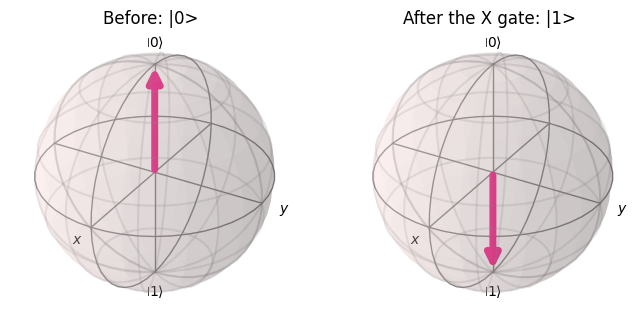

In [13]:
fig = plt.figure(figsize=(8, 3.8))
ax = fig.add_subplot(1, 2, 1, projection="3d")
plot_bloch_vector([0, 0, 1], ax=ax); ax.set_title("Before: |0>", y=1.1)
ax = fig.add_subplot(1, 2, 2, projection="3d")
plot_bloch_vector([0, 0, -1], ax=ax); ax.set_title("After the X gate: |1>", y=1.1)
plt.show()

**What to notice:** on the Bloch sphere the X gate is a half-turn about the x-axis, which takes the north pole to the south pole.

## 5. Measurement by hand: a ten-line quantum computer

A simulator is not magic. For one qubit it does three things:

1. keep the two amplitudes,
2. apply gates by matrix multiplication (Section 4),
3. when measuring, pick 0 or 1 **at random with the Born-rule probabilities**, then **collapse** the state to match.

Here is exactly that in NumPy. `rng.choice([0, 1], p=...)` is a weighted coin flip.

In [14]:
rng = np.random.default_rng(seed=1)    # seed makes the random numbers repeatable

def measure(state):
    p = probabilities(state)
    outcome = int(rng.choice([0, 1], p=p))         # weighted coin flip
    collapsed = ket0 if outcome == 0 else ket1     # the state after measuring
    return outcome, collapsed

outcome, after = measure(psi)
print("Measured psi = [0.6, 0.8] once ->", outcome, "   state is now", after.tolist())

print("Measuring that same qubit again 5 times:", [measure(after)[0] for _ in range(5)])

Measured psi = [0.6, 0.8] once -> 1    state is now [0, 1]
Measuring that same qubit again 5 times: [1, 1, 1, 1, 1]


**What to notice:** once measured, the qubit stays put. Re-measuring repeats the same answer, because the superposition is gone (**collapse**).

So to learn the probabilities we must prepare a **fresh** copy each time and measure it once. Each fresh prepare-and-measure is a **shot**:

In [15]:
def run_shots(state, shots):
    results = [measure(state)[0] for _ in range(shots)]   # fresh copy every time
    return Counter(results)

print("psi, 1000 shots:      ", dict(run_shots(psi, 1000)))
print("X|0> = |1>, 1000 shots:", dict(run_shots(X @ ket0, 1000)))
print("|0>, 1000 shots:       ", dict(run_shots(ket0, 1000)))

psi, 1000 shots:       {1: 639, 0: 361}
X|0> = |1>, 1000 shots: {1: 1000}
|0>, 1000 shots:        {0: 1000}


**What to notice:** our home-made machine already reproduces the course notebook. X|0⟩ gives 1 all 1000 times and
the untouched |0⟩ gives 0 all 1000 times. For `psi` the count of 1s lands near 640 but not exactly on it, because the outcomes are random.

## 6. The course notebook's circuit, rebuilt

Now the real Qiskit version, the same three steps as cells 4–6 of the course notebook.

`QuantumCircuit(1, 1)` = 1 qubit (register `q`) + 1 classical bit (register `c`) to store the answer.
`print(circuit)` draws it with text characters.

In [16]:
circuit = QuantumCircuit(1, 1)
print(circuit)

     
  q: 
     
c: 1/
     


`circuit.x(0)` adds an X gate on qubit number 0 (Python counts from 0). `draw("mpl")` draws a picture with matplotlib.

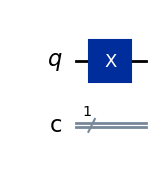

In [17]:
circuit.x(0)
circuit.draw("mpl")

`circuit.measure(0, 0)` = "measure qubit 0, store the result in classical bit 0".
In the picture: the grey meter is the measurement; the double line is the classical wire; the arrow and the small **0** show the result going into classical bit 0.

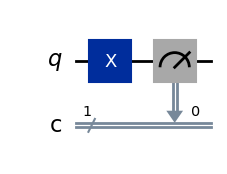

In [18]:
circuit.measure(0, 0)
circuit.draw("mpl")

In [19]:
print(circuit)    # the same circuit as text

     ┌───┐┌─┐
  q: ┤ X ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


A circuit is just a list of instructions. You can inspect it:

In [20]:
print("qubits:", circuit.num_qubits, "| classical bits:", circuit.num_clbits)
print("operation counts:", dict(circuit.count_ops()))
print()
for step, instruction in enumerate(circuit.data, start=1):
    qubits = [circuit.find_bit(q).index for q in instruction.qubits]
    clbits = [circuit.find_bit(c).index for c in instruction.clbits]
    print(f"step {step}: {instruction.operation.name:8} on qubit(s) {qubits}  classical bit(s) {clbits}")

qubits: 1 | classical bits: 1
operation counts: {'x': 1, 'measure': 1}

step 1: x        on qubit(s) [0]  classical bit(s) []
step 2: measure  on qubit(s) [0]  classical bit(s) [0]


## 7. Running on the simulator: shots and counts

`AerSimulator()` is Qiskit's version of the ten-line machine from Section 5: same maths, much faster, and it handles many qubits.

The chain `simulator.run(...)` → `.result()` → `.get_counts()` is split into separate lines below so you can see each piece.

In [21]:
simulator = AerSimulator()

job = simulator.run(circuit, shots=1000)   # a 'job': a ticket for work in progress
result = job.result()                       # wait for it to finish, get the result object
counts = result.get_counts()                # the tally of outcomes

print("type of counts:", type(counts).__name__)
print("counts:", counts)

type of counts: Counts
counts: {'1': 1000}


`counts` is a **dictionary**: outcome → how many shots gave it. Outcomes that never happened are left out, so use `.get(key, 0)` to ask safely:

In [22]:
print("counts['1']        =", counts["1"])
print("counts.get('0', 0) =", counts.get("0", 0), "  <- '0' never happened, so it is not in the dictionary")
print("total shots        =", sum(counts.values()))
print("share of 1s        =", counts.get("1", 0) / sum(counts.values()))

counts['1']        = 1000
counts.get('0', 0) = 0   <- '0' never happened, so it is not in the dictionary
total shots        = 1000
share of 1s        = 1.0


With `memory=True` the simulator also returns every individual shot, in order. Here are the first 20:

In [23]:
shots_list = simulator.run(circuit, shots=20, memory=True).result().get_memory()
print(shots_list)

['1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1']


**What to notice:** every single shot is `'1'`. The state just before measurement is |1⟩, so P(1) = 100%. There is no randomness at all in this circuit.

## 8. Histograms and the control experiment

`plot_histogram` draws the counts as a bar chart (cell 9 of the course notebook):

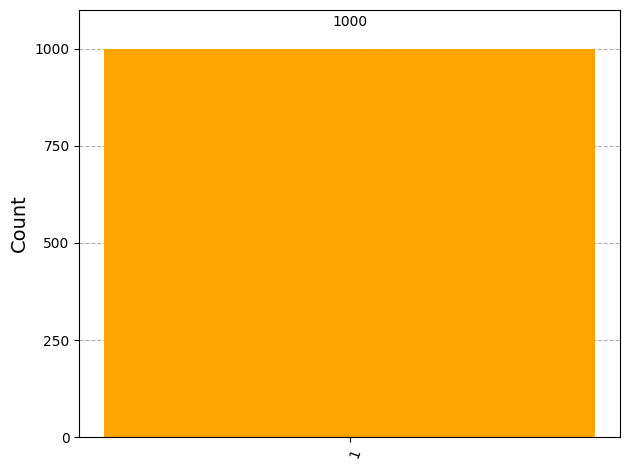

In [24]:
plot_histogram(counts, color="orange")

It is only a bar chart. Here is the same thing drawn by hand with matplotlib, this time including the empty '0' bar:

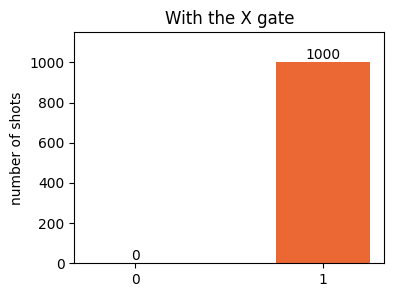

In [25]:
outcomes = ["0", "1"]
values = [counts.get(o, 0) for o in outcomes]
plt.figure(figsize=(4, 3))
plt.bar(outcomes, values, color=[C0, C1], width=0.5)
for x, v in enumerate(values):
    plt.text(x, v + 15, str(v), ha="center")
plt.ylabel("number of shots")
plt.title("With the X gate")
plt.ylim(0, 1150)
plt.show()

The course notebook then runs a **control experiment**: the same circuit with **no** X gate, to show what an untouched qubit does.
That way you know the X gate caused the change.

In [26]:
default_circuit = QuantumCircuit(1, 1)
default_circuit.measure(0, 0)

default_counts = simulator.run(default_circuit, shots=1000).result().get_counts()
print("no gate:  ", default_counts)
print("with X:   ", counts)

no gate:   {'0': 1000}
with X:    {'1': 1000}


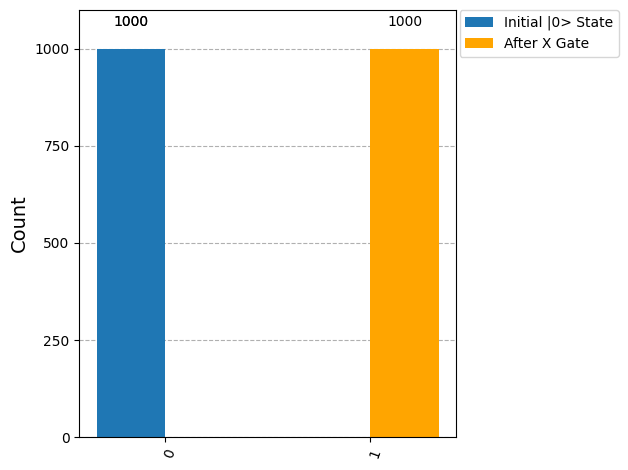

In [27]:
plot_histogram(
    [default_counts, counts],
    legend=["Initial |0> State", "After X Gate"],
    color=["#1f77b4", "orange"],
)

**What to notice:** the whole story of the course notebook in one picture. Every qubit starts in |0⟩ (blue, all 0s), and the X gate moves every result to 1 (orange).

## 9. A common mistake: re-running a cell adds gates

`circuit.x(0)` **adds** an X gate to the existing circuit. If you run that cell twice, the circuit gets two X gates,
and two X gates cancel (Section 4). Below we do it on purpose with a fresh circuit called `oops`.

In [28]:
oops = QuantumCircuit(1, 1)
oops.x(0)
oops.x(0)          # <- as if the 'circuit.x(0)' cell had been run a second time
oops.measure(0, 0)
print(oops)
print("counts:", simulator.run(oops, shots=1000).result().get_counts())

     ┌───┐┌───┐┌─┐
  q: ┤ X ├┤ X ├┤M├
     └───┘└───┘└╥┘
c: 1/═══════════╩═
                0 
counts: {'0': 1000}


**What to notice:** the result silently became `{'0': 1000}`. If a diagram or result ever looks wrong, use
**Kernel → Restart Kernel and Run All Cells** so every cell runs exactly once, top to bottom.

## 10. Why shots matter: a qubit that is *not* certain

In the course notebook every outcome is certain, so the 1000 shots are overkill. To see why shots exist, let's prepare the
uncertain state $[0.6, 0.8]$ (36% → 0, 64% → 1) on a real Qiskit circuit.

We use an `ry` gate, a rotation that works like a dial for the blend. You don't need to understand it yet; Notebook 11 covers it.
The angle $\theta = 2\arcsin(0.8)$ is chosen so the amplitudes come out as exactly 0.6 and 0.8:

state: [0.6 0.8]


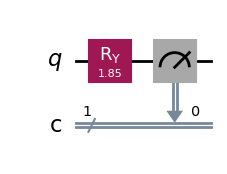

In [29]:
theta = 2 * np.arcsin(0.8)

blend = QuantumCircuit(1, 1)
blend.ry(theta, 0)

print("state:", Statevector.from_instruction(blend).data.real.round(4))   # check: [0.6, 0.8]

blend.measure(0, 0)
blend.draw("mpl")

Now measure it with more and more shots. The **rule of thumb** for the typical error of the measured share is

$$\text{typical error} \approx \sqrt{\frac{p\,(1-p)}{N}}, \qquad p = 0.64,\ N = \text{shots}.$$

In [30]:
p_true = 0.64
print(f"{'shots':>7} {'counts':>24} {'share of 1s':>12} {'off by':>8} {'rule of thumb':>14}")
for shots in [10, 100, 1000, 10000, 100000]:
    c = simulator.run(blend, shots=shots).result().get_counts()
    share = c.get("1", 0) / shots
    typical = np.sqrt(p_true * (1 - p_true) / shots)
    print(f"{shots:7d} {str(c):>24} {share:12.2%} {abs(share - p_true):8.2%} {typical:13.2%}")

  shots                   counts  share of 1s   off by  rule of thumb
     10         {'1': 7, '0': 3}       70.00%    6.00%        15.18%
    100       {'0': 37, '1': 63}       63.00%    1.00%         4.80%
   1000     {'1': 624, '0': 376}       62.40%    1.60%         1.52%


  10000   {'0': 3596, '1': 6404}       64.04%    0.04%         0.48%
 100000 {'1': 63894, '0': 36106}       63.89%    0.11%         0.15%


**What to notice:** the error shrinks as shots grow, roughly like the rule of thumb says. Ten times more shots makes the error about $\sqrt{10} \approx 3.2$ times smaller.

The next plot follows one long run, shot by shot. The orange line is the share of 1s so far; the shaded band is the rule-of-thumb range (±2 typical errors).

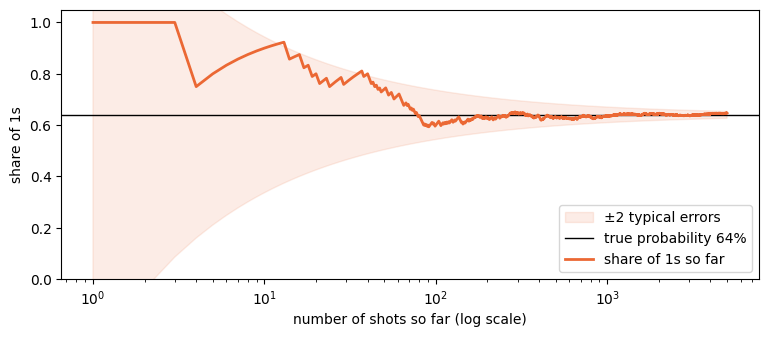

In [31]:
memory = simulator.run(blend, shots=5000, memory=True).result().get_memory()
bits = np.array([int(b) for b in memory])
n = np.arange(1, len(bits) + 1)
running_share = np.cumsum(bits) / n
band = 2 * np.sqrt(p_true * (1 - p_true) / n)

plt.figure(figsize=(9, 3.5))
plt.fill_between(n, p_true - band, p_true + band, color=C1, alpha=0.12, label="±2 typical errors")
plt.axhline(p_true, color="black", lw=1, label="true probability 64%")
plt.plot(n, running_share, color=C1, lw=2, label="share of 1s so far")
plt.xscale("log"); plt.ylim(0, 1.05)
plt.xlabel("number of shots so far (log scale)"); plt.ylabel("share of 1s")
plt.legend(loc="lower right")
plt.show()

Finally: if you repeat the *whole* 1000-shot experiment many times, how much does the count of 1s jump around?
The rule of thumb predicts a spread of about $\sqrt{1000 \times 0.64 \times 0.36} \approx 15$ counts around 640.

average count of 1s: 640.4   (expected 640)
typical spread:      15.4   (expected about 15.2)


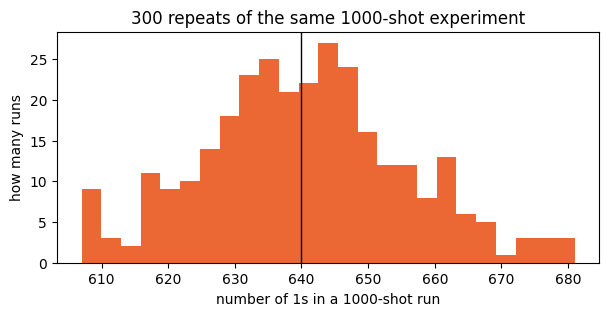

In [32]:
repeats = [simulator.run(blend, shots=1000).result().get_counts().get("1", 0) for _ in range(300)]

print(f"average count of 1s: {np.mean(repeats):.1f}   (expected 640)")
print(f"typical spread:      {np.std(repeats):.1f}   (expected about {np.sqrt(1000 * 0.64 * 0.36):.1f})")

plt.figure(figsize=(7, 3))
plt.hist(repeats, bins=25, color=C1)
plt.axvline(640, color="black", lw=1)
plt.xlabel("number of 1s in a 1000-shot run"); plt.ylabel("how many runs")
plt.title("300 repeats of the same 1000-shot experiment")
plt.show()

**What to notice:** a single 1000-shot run of this circuit can land anywhere from about 610 to 670 without anything being wrong.
That is why the 1000 shots matter from Notebook 02 onward.

## 11. Bonus: what a real, noisy machine might say

`AerSimulator()` is perfect. Real hardware sometimes misreads the qubit. Here we tell the simulator to misread 2.5% of the time
(a **readout error**) and re-run the course notebook's X circuit. Notebook 13 explores noise properly.

In [33]:
from qiskit_aer.noise import NoiseModel, ReadoutError

misread = 0.025
noise = NoiseModel()
noise.add_all_qubit_readout_error(ReadoutError([[1 - misread, misread],
                                                [misread, 1 - misread]]))
noisy_simulator = AerSimulator(noise_model=noise)

noisy_counts = noisy_simulator.run(circuit, shots=1000).result().get_counts()
print("perfect simulator:", counts)
print("noisy simulator:  ", noisy_counts)

perfect simulator: {'1': 1000}
noisy simulator:   {'1': 977, '0': 23}


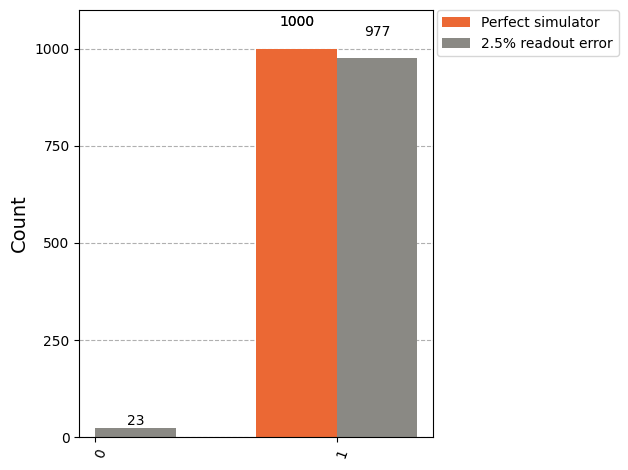

In [34]:
plot_histogram([counts, noisy_counts], legend=["Perfect simulator", "2.5% readout error"], color=[C1, "#8a8984"])

## 12. Exercises

Try each one *before* looking at the solutions further down. Write your answer in the empty cell under each question.

**Exercise 1.** Predict the counts for a circuit that applies **three** X gates to a fresh qubit and then measures (1000 shots). Then check.

In [35]:
# Your code for Exercise 1


**Exercise 2.** A qubit has amplitudes $[0.28, 0.96]$. Work out P(0) and P(1) by hand, then check with `probabilities()`. Is it a valid state?

In [36]:
# Your code for Exercise 2


**Exercise 3.** Build a circuit with **2 qubits and 2 classical bits**. Apply X to qubit 1 only, measure qubit 0 into bit 0 and qubit 1 into bit 1.
Which bit string appears in the counts: `'01'` or `'10'`? (Hint: Qiskit writes qubit 0 as the **rightmost** character.)

In [37]:
# Your code for Exercise 3


**Exercise 4.** Using the rule of thumb, how many shots would you need so that the typical error for $p = 0.64$ is only 0.5 percentage points (0.005)?

In [38]:
# Your code for Exercise 4


**Exercise 5.** Run the course notebook's `circuit` with `shots=1`. What do the counts look like, and why is one shot enough *for this circuit*?

In [39]:
# Your code for Exercise 5


---
## Solutions

**Solution 1.** Three X gates = X·X·X = (X·X)·X = I·X = X, so the qubit ends up as |1⟩: expect `{'1': 1000}`.

In [40]:
three_x = QuantumCircuit(1, 1)
three_x.x(0); three_x.x(0); three_x.x(0)
three_x.measure(0, 0)
print(simulator.run(three_x, shots=1000).result().get_counts())

{'1': 1000}


**Solution 2.** $0.28^2 = 0.0784$ and $0.96^2 = 0.9216$. They add to exactly 1, so it is valid: about 7.8% → 0 and 92.2% → 1.

In [41]:
state = np.array([0.28, 0.96])
print("probabilities:", probabilities(state), " sum:", probabilities(state).sum(), " valid:", is_valid_state(state))

probabilities: [0.0784 0.9216]  sum: 1.0  valid: True


**Solution 3.** Qubit 1 reads 1 and qubit 0 reads 0. Qiskit prints bit 1 on the left and bit 0 on the right, so the string is `'10'`.
This ordering matters from Notebook 04 onward.

In [42]:
two = QuantumCircuit(2, 2)
two.x(1)
two.measure([0, 1], [0, 1])
print(two)
print(simulator.run(two, shots=1000).result().get_counts())

          ┌─┐   
q_0: ─────┤M├───
     ┌───┐└╥┘┌─┐
q_1: ┤ X ├─╫─┤M├
     └───┘ ║ └╥┘
c: 2/══════╩══╩═
           0  1 
{'10': 1000}


**Solution 4.** Solve $\sqrt{p(1-p)/N} = 0.005$ for $N$: $N = p(1-p)/0.005^2 = 0.2304 / 0.000025 = 9216$ shots.
Halving the error always costs four times the shots.

In [43]:
p = 0.64
target = 0.005
print(f"shots needed: {p * (1 - p) / target**2:.0f}")

shots needed: 9216


**Solution 5.** `{'1': 1}`. The outcome is certain (P(1) = 100%), so a single shot already tells you everything.
Shots only matter when outcomes are random, as in Section 10.

In [44]:
print(simulator.run(circuit, shots=1).result().get_counts())

{'1': 1}


---
## Cheat sheet

| Code | Meaning |
|---|---|
| `QuantumCircuit(1, 1)` | new circuit: 1 qubit, 1 classical bit |
| `circuit.x(0)` | add an X gate (quantum NOT) on qubit 0 |
| `circuit.measure(0, 0)` | measure qubit 0, store the result in classical bit 0 |
| `circuit.draw("mpl")` / `print(circuit)` | draw the circuit as a picture / as text |
| `Statevector.from_instruction(qc)` | the exact amplitudes a (measurement-free) circuit produces |
| `AerSimulator()` | a perfect quantum-computer simulator |
| `simulator.run(circuit, shots=1000).result()` | run 1000 shots and wait for the result |
| `result.get_counts()` | dictionary: outcome → how many shots gave it |
| `counts.get('0', 0)` | look up an outcome safely (0 if it never happened) |
| `plot_histogram(counts)` | bar chart of the counts |

**The three facts Notebook 01 demonstrates:** qubits start in |0⟩; the X gate flips |0⟩ to |1⟩; measuring |0⟩ or |1⟩ gives a certain answer.

**Next:** Notebook 02 swaps the X gate for a Hadamard (H) gate, which creates a 50/50 superposition. That is where Section 10 of this notebook becomes the main event.